# Q12 SuperTrend 替代 LVT 内部趋势确认

Q12 研究问题：

> 如果不在 LVT 外面再套 SuperTrend，而是直接把 LVT 内部的趋势确认替换成 SuperTrend，会不会更好？

Q8/Q11 的实盘化口径保持不变：

- Core80 / Expanded satellite20 / Def200 Cash
- fixed twice-monthly signals
- close-signal-next-day-trade
- 20 bps base cost + asset friction
- 2% minimum rebalance threshold
- 15% max single-ETF trade per rebalance

只改变卫星 selector 的趋势确认方式。低波排序、Top3、RiskParity cap50、成本、执行、窗口全部保持一致。


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q12-supertrend-replace-lvt-trend-confirmation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
DEFENSE_WINDOW = 200
BASE_COST_BPS = 20
THRESHOLD = 0.02
MAX_TRADE = 0.15
DEFAULT_ATR = 10
DEFAULT_MULTIPLIER = 3.0

WINDOWS = {
    "full_sample": (None, None),
    "2021_to_date": ("2021-01-01", None),
    "2022_bear": ("2022-01-01", "2022-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

ASSET_EXTRA_FRICTION_BPS = {
    CSI300: 5,
    GOLD: 5,
    DIVIDEND: 5,
    NASDAQ: 20,
    HK_TECH: 20,
    NONFERROUS: 10,
    CHIP: 10,
    COMM: 10,
    ENERGY: 10,
    BROKER: 10,
    HEALTHCARE: 10,
}

STRATEGY_DEFINITIONS = {
    "Q8_Original_LVT": "Original LVT: price > MA60, 63D momentum > 0, then choose lowest-vol Top3.",
    "ST_Replaces_MA_Mom": "Direct replacement: SuperTrend long, then choose lowest-vol Top3. No MA60 or momentum gate.",
    "ST_Replaces_MA_KeepMom": "Replace MA60 only: SuperTrend long plus 63D momentum > 0, then choose lowest-vol Top3.",
    "MA_Mom_AND_ST": "Strict internal confirmation: original LVT gate and SuperTrend long must both pass.",
    "MA_Mom_OR_ST": "Loose internal confirmation: original LVT gate or SuperTrend long passes.",
    "Q11_EntryFilter_Reference": "Q11 external reference: LVT new entries require SuperTrend long, existing LVT names may stay until LVT drops them.",
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")


Output dir: outputs/q12-supertrend-replace-lvt-trend-confirmation
End date request: 2026-06-25


## 数据下载与基础函数


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if len(col) > 1 and col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["close"]).copy()
    df.index = pd.DatetimeIndex(df.index).tz_localize(None).normalize()
    return df


raw = {sym: download_symbol(sym) for sym in ALL_SYMBOLS}
index = pd.DatetimeIndex(sorted(set().union(*[set(df.index) for df in raw.values()])))

open_raw = pd.DataFrame({sym: raw[sym]["open"].reindex(index) for sym in ALL_SYMBOLS})
high_raw = pd.DataFrame({sym: raw[sym]["high"].reindex(index) for sym in ALL_SYMBOLS})
low_raw = pd.DataFrame({sym: raw[sym]["low"].reindex(index) for sym in ALL_SYMBOLS})
close_raw = pd.DataFrame({sym: raw[sym]["close"].reindex(index) for sym in ALL_SYMBOLS})
volume_raw = pd.DataFrame({sym: raw[sym]["volume"].reindex(index) for sym in ALL_SYMBOLS})

open_ = open_raw.ffill()
high = high_raw.ffill()
low = low_raw.ffill()
close = close_raw.ffill()
volume = volume_raw.fillna(0.0)
returns = close.pct_change(fill_method=None)
value_traded = close_raw * volume_raw
adv20 = value_traded.fillna(0.0).rolling(20, min_periods=5).mean()

availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "price_rows": int(close_raw[sym].dropna().shape[0]),
        "volume_rows": int(volume_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)
print(f"Backtest calendar: {close.index[0].date()} to {close.index[-1].date()}, rows={len(close)}")


,symbol,name,first_date,last_date,price_rows,volume_rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-24,1566,1566
1,513100.SS,纳指100ETF,2020-01-02,2026-06-24,1567,1567
2,518880.SS,黄金ETF,2020-01-02,2026-06-24,1566,1566
3,512400.SS,有色金属ETF,2020-01-02,2026-06-24,1566,1566
4,159995.SZ,芯片ETF,2020-01-20,2026-06-24,1548,1548
5,515880.SS,通信ETF,2020-01-02,2026-06-24,1566,1566
6,510880.SS,红利ETF,2020-01-02,2026-06-24,1566,1566
7,159930.SZ,能源ETF,2020-01-02,2026-06-24,1544,1544
8,512880.SS,证券ETF,2020-01-02,2026-06-24,1566,1566
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-24,1234,1234


Backtest calendar: 2020-01-02 to 2026-06-24, rows=1567


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def signal_dates(index):
    idx = pd.DatetimeIndex(index)
    dates = []
    months = pd.period_range(idx.min().to_period("M"), idx.max().to_period("M"), freq="M")
    for p in months:
        for day in (10, 25):
            anchor = pd.Timestamp(year=p.year, month=p.month, day=min(day, p.days_in_month))
            pos = idx.searchsorted(anchor)
            if pos < len(idx) and idx[pos].to_period("M") == p:
                dates.append(idx[pos])
    return set(pd.DatetimeIndex(sorted(set(dates))))


SDATES = signal_dates(close.index)


def enough_history(sym, loc, window):
    if loc < window:
        return False
    return close[sym].iloc[loc - window + 1:loc + 1].notna().all()


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    return returns[sym].iloc[loc - window + 1:loc + 1].notna().all()


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    return apply_cap((inv / inv.sum()).to_dict(), universe, cap)


def base_features(date, universe=EXPANDED_THEME):
    loc = close.index.get_loc(date)
    rows = {}
    for sym in universe:
        if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)) or not enough_return_history(sym, loc, VOL_WINDOW):
            rows[sym] = {"valid": False, "ma_pass": False, "mom_pass": False, "vol": np.nan}
            continue
        price = close.at[date, sym]
        ma = close[sym].iloc[loc - MA_WINDOW + 1:loc + 1].mean()
        mom = price / close[sym].iloc[loc - MOM_WINDOW] - 1.0
        vol = returns[sym].iloc[loc - VOL_WINDOW + 1:loc + 1].std(ddof=1)
        rows[sym] = {"valid": True, "ma_pass": price > ma, "mom_pass": mom > 0, "vol": vol}
    return pd.DataFrame(rows).T


def low_vol_top3_from_eligible(date, eligible):
    feats = base_features(date)
    eligible = [sym for sym in eligible if sym in feats.index and bool(feats.at[sym, "valid"])]
    if not eligible:
        return []
    return feats.loc[eligible, "vol"].astype(float).sort_values().head(TOP_N).index.tolist()


def allocate_satellite(date, eligible):
    return risk_parity_weight(date, eligible, EXPANDED_THEME, CAP)


## SuperTrend 与内部 selector


In [4]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr
    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue
        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]
        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish


_ST_CACHE = {}


def supertrend_matrix(atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    key = (atr_period, float(multiplier))
    if key not in _ST_CACHE:
        _ST_CACHE[key] = pd.DataFrame({sym: supertrend_signal_for_symbol(sym, atr_period, multiplier)[1] for sym in EXPANDED_THEME}).fillna(False)
    return _ST_CACHE[key]


def select_assets(kind, date, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, last_active=None):
    feats = base_features(date)
    valid = feats.index[feats["valid"].astype(bool)].tolist()
    original_gate = set(feats.index[feats["valid"].astype(bool) & feats["ma_pass"].astype(bool) & feats["mom_pass"].astype(bool)])
    mom_gate = set(feats.index[feats["valid"].astype(bool) & feats["mom_pass"].astype(bool)])
    st = supertrend_matrix(atr, multiplier).loc[date]
    st_gate = {sym for sym in valid if bool(st[sym])}
    last_active = set() if last_active is None else set(last_active)

    if kind == "Q8_Original_LVT":
        eligible = original_gate
    elif kind == "ST_Replaces_MA_Mom":
        eligible = st_gate
    elif kind == "ST_Replaces_MA_KeepMom":
        eligible = st_gate & mom_gate
    elif kind == "MA_Mom_AND_ST":
        eligible = original_gate & st_gate
    elif kind == "MA_Mom_OR_ST":
        eligible = original_gate | st_gate
    elif kind == "Q11_EntryFilter_Reference":
        lvt = original_gate
        eligible = {sym for sym in lvt if (sym in st_gate) or (sym in last_active)}
    else:
        raise ValueError(kind)
    return low_vol_top3_from_eligible(date, eligible)


def build_satellite_weights(kind, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    rows = []
    last = normalize_weights({}, EXPANDED_THEME)
    for date in close.index:
        if date in SDATES:
            last_active = {sym for sym in EXPANDED_THEME if last.get(sym, 0.0) > 1e-10}
            selected = select_assets(kind, date, atr=atr, multiplier=multiplier, last_active=last_active)
            last = allocate_satellite(date, selected)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(EXPANDED_THEME) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(EXPANDED_THEME) + ["CASH"]]


## 核心防守、组合执行和成本


In [5]:
def build_signal_weights(universe, selector, allocator):
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in SDATES:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def build_core_def200_weights():
    core = build_signal_weights(
        CORE_ASSETS,
        lambda _date: list(CORE_ASSETS),
        lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None),
    )
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in SDATES:
            loc = close.index.get_loc(date)
            base = core.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, DEFENSE_WINDOW) and close.at[date, sym] > close[sym].iloc[loc - DEFENSE_WINDOW + 1:loc + 1].mean()
                if not risk_on:
                    moved = base[sym]
                    base[sym] = 0.0
                    base["CASH"] += moved
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


def expand_weights(weights):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_core_satellite(core_weights, satellite_weights):
    out = 0.80 * expand_weights(core_weights) + 0.20 * expand_weights(satellite_weights)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    return out.div(total.replace(0, np.nan), axis=0).fillna(0.0)


def apply_execution_timing(target_weights):
    cols = list(ALL_SYMBOLS) + ["CASH"]
    executed_rows = []
    current = pd.Series(0.0, index=cols)
    current["CASH"] = 1.0
    pending = None
    for i, date in enumerate(close.index):
        if pending is not None and pending["execute_date"] == date:
            desired = pending["target"]
            turnover = 0.5 * (desired - current).abs().sum()
            if turnover >= THRESHOLD - 1e-12:
                asset_cols = list(ALL_SYMBOLS)
                delta = (desired[asset_cols] - current[asset_cols]).clip(lower=-MAX_TRADE, upper=MAX_TRADE)
                new_assets = (current[asset_cols] + delta).clip(lower=0.0)
                asset_sum = new_assets.sum()
                if asset_sum > 1.0:
                    new_assets = new_assets / asset_sum
                    cash = 0.0
                else:
                    cash = 1.0 - asset_sum
                current = pd.concat([new_assets, pd.Series({"CASH": cash})]).reindex(cols).fillna(0.0)
            pending = None
        if date in SDATES:
            execute_idx = min(i + 1, len(close.index) - 1)
            pending = {"execute_date": close.index[execute_idx], "target": target_weights.loc[date, cols].copy()}
        executed_rows.append(current.to_dict())
    return pd.DataFrame(executed_rows, index=close.index, columns=cols)


def turnover_by_asset(weights):
    prev = weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    return (weights[list(ALL_SYMBOLS)] - prev).abs().fillna(0.0)


def friction_cost_series(weights):
    asset_turnover = turnover_by_asset(weights)
    cost_bps = pd.Series(BASE_COST_BPS, index=ALL_SYMBOLS, dtype=float)
    extra = pd.Series({sym: ASSET_EXTRA_FRICTION_BPS[sym] for sym in ALL_SYMBOLS})
    cost_bps = cost_bps + extra
    return (asset_turnover * (cost_bps / 10000.0)).sum(axis=1)


def backtest(name, target, satellite):
    executed = apply_execution_timing(target)
    asset_weights = executed[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)].fillna(0.0)).sum(axis=1)
    costs = friction_cost_series(executed)
    net = gross - costs
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {
        "name": name,
        "target": target,
        "satellite": satellite,
        "weights": executed,
        "returns": net,
        "gross_returns": gross,
        "costs": costs,
        "nav": nav,
    }


core_def200 = build_core_def200_weights()
satellites = {kind: build_satellite_weights(kind) for kind in STRATEGY_DEFINITIONS}
targets = {kind: combine_core_satellite(core_def200, sat) for kind, sat in satellites.items()}
portfolios = {kind: backtest(kind, targets[kind], satellites[kind]) for kind in STRATEGY_DEFINITIONS}

latest_targets = []
for kind, target in targets.items():
    row = {"strategy": kind, "definition": STRATEGY_DEFINITIONS[kind]}
    row.update({SYMBOL_NAMES.get(sym, sym): target[sym].iloc[-1] for sym in ALL_SYMBOLS})
    row["现金"] = target["CASH"].iloc[-1]
    latest_targets.append(row)
latest_targets = pd.DataFrame(latest_targets)
latest_targets.to_csv(OUTPUT_DIR / "latest_target_weights.csv", index=False, encoding="utf-8-sig")
display(latest_targets.round(4))


,strategy,definition,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,Q8_Original_LVT,"Original LVT: price > MA60, 63D momentum > 0, ...",0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.000,0.0,0.0,0.0,0.0
1,ST_Replaces_MA_Mom,"Direct replacement: SuperTrend long, then choo...",0.3538,0.2101,0.2781,0.0,0.0000,0.0000,0.1,0.058,0.0,0.0,0.0,0.0
2,ST_Replaces_MA_KeepMom,Replace MA60 only: SuperTrend long plus 63D mo...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.000,0.0,0.0,0.0,0.0
3,MA_Mom_AND_ST,Strict internal confirmation: original LVT gat...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.000,0.0,0.0,0.0,0.0
4,MA_Mom_OR_ST,Loose internal confirmation: original LVT gate...,0.3538,0.2101,0.2781,0.0,0.0000,0.0000,0.1,0.058,0.0,0.0,0.0,0.0
5,Q11_EntryFilter_Reference,Q11 external reference: LVT new entries requir...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0,0.000,0.0,0.0,0.0,0.0


## 指标函数


In [6]:
def period_slice(obj, start, end):
    out = obj.copy()
    if start is not None:
        out = out.loc[pd.Timestamp(start):]
    if end is not None:
        out = out.loc[:pd.Timestamp(end)]
    if isinstance(out, pd.DataFrame):
        return out.dropna(how="all")
    return out.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def drawdown_events_from_nav(nav):
    dd = drawdown_series(nav).dropna()
    events = []
    in_dd = False
    start_i = trough_i = None
    start_date = trough_date = None
    trough_value = 0.0
    for i, (date, value) in enumerate(dd.items()):
        if not in_dd and value < -1e-12:
            in_dd = True
            start_i = trough_i = i
            start_date = trough_date = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough_i = i
                trough_date = date
                trough_value = value
            if value >= -1e-12:
                events.append({
                    "开始日期": pd.Timestamp(start_date).date(),
                    "最低点日期": pd.Timestamp(trough_date).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌交易日": trough_i - start_i,
                    "修复交易日": i - trough_i,
                    "总交易日": i - start_i,
                })
                in_dd = False
    if in_dd and start_date is not None:
        events.append({
            "开始日期": pd.Timestamp(start_date).date(),
            "最低点日期": pd.Timestamp(trough_date).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌交易日": trough_i - start_i,
            "修复交易日": np.nan,
            "总交易日": len(dd) - 1 - start_i,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def recovery_stats(nav):
    events = drawdown_events_from_nav(nav)
    if events.empty:
        return {"平均修复天数": 0.0, "最长修复天数": 0.0, "未修复回撤": 0.0, "未修复已持续天数": 0}
    recovery_numeric = pd.to_numeric(events["修复交易日"], errors="coerce")
    recovered = events[recovery_numeric.notna()]
    unresolved = events[recovery_numeric.isna()]
    current = unresolved.iloc[-1] if len(unresolved) else None
    return {
        "平均修复天数": recovered["修复交易日"].mean() if len(recovered) else np.nan,
        "最长修复天数": recovered["修复交易日"].max() if len(recovered) else np.nan,
        "未修复回撤": current["深度"] if current is not None else 0.0,
        "未修复已持续天数": current["总交易日"] if current is not None else 0,
    }


def metrics_row(name, port, start, end):
    r = period_slice(port["returns"], start, end).fillna(0.0)
    w = period_slice(port["weights"], start, end).fillna(0.0)
    costs = period_slice(port["costs"], start, end).fillna(0.0)
    sat = period_slice(port["satellite"], start, end).fillna(0.0)
    core = period_slice(core_def200, start, end).fillna(0.0)
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    downside = r[r < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = ann / downside_dev if downside_dev and downside_dev > 0 else np.nan
    dd = drawdown_series(nav)
    mdd = float(dd.min()) if len(dd) else np.nan
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    under = dd < -1e-12
    asset_turnover = turnover_by_asset(w).sum(axis=1)
    rec = recovery_stats(nav)
    row = {
        "strategy": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "Sharpe": sharpe,
        "Calmar": calmar,
        "Sortino": sortino,
        "月度胜率": (monthly > 0).mean() if len(monthly) else np.nan,
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最差月": monthly.min() if len(monthly) else np.nan,
        "最好月": monthly.max() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
        "水下时间占比": float(under.mean()) if len(under) else np.nan,
        "平均水下": float(dd[under].mean()) if under.any() else 0.0,
        "最长水下天数": max_consecutive(under) if len(under) else 0,
        "超过-10%天数": int((dd <= -0.10).sum()) if len(dd) else 0,
        "年化换手": asset_turnover.sum() / years,
        "交易成本拖累": costs.sum(),
        "年化成本拖累": costs.sum() / years,
        "平均现金/Def200权重": w["CASH"].mean(),
        "平均核心Def200现金": 0.80 * core["CASH"].mean() if len(core) else np.nan,
        "平均卫星现金": 0.20 * sat["CASH"].mean() if len(sat) else np.nan,
        "平均风险资产暴露": 1.0 - w["CASH"].mean(),
        **rec,
    }
    for sym in ALL_SYMBOLS:
        row[f"当前权重_{SYMBOL_NAMES[sym]}"] = w[sym].iloc[-1] if len(w) else np.nan
    row["当前权重_现金"] = w["CASH"].iloc[-1] if len(w) else np.nan
    return row


def annual_returns_from_port(port, start, end):
    r = period_slice(port["returns"], start, end).fillna(0.0)
    return r.resample("YE").apply(lambda x: (1.0 + x).prod() - 1.0).rename(port["name"])


## 主策略评估


In [7]:
summary_rows = []
for window, (start, end) in WINDOWS.items():
    for name, port in portfolios.items():
        row = metrics_row(name, port, start, end)
        row["window"] = window
        row["definition"] = STRATEGY_DEFINITIONS[name]
        summary_rows.append(row)

summary_all = pd.DataFrame(summary_rows)
summary_all.to_csv(OUTPUT_DIR / "summary_all_windows.csv", index=False, encoding="utf-8-sig")

key_cols = [
    "window", "strategy", "累计收益", "年化收益", "年化波动", "最大回撤", "Sharpe", "Calmar", "Sortino",
    "月度胜率", "最差月", "最好月", "盈利因子", "水下时间占比", "平均水下", "最长水下天数", "超过-10%天数",
    "平均修复天数", "最长修复天数", "未修复回撤", "年化换手", "年化成本拖累", "平均现金/Def200权重", "平均卫星现金", "平均风险资产暴露",
]
display(summary_all[summary_all["window"] == "2021_to_date"][key_cols].round(4))

annual_tables = []
for window, (start, end) in WINDOWS.items():
    annual = pd.DataFrame({name: annual_returns_from_port(port, start, end) for name, port in portfolios.items()})
    annual.index = annual.index.year
    annual.to_csv(OUTPUT_DIR / f"annual_returns_{window}.csv", encoding="utf-8-sig")
    annual_tables.append(annual.assign(window=window).reset_index(names="year"))
pd.concat(annual_tables, ignore_index=True).to_csv(OUTPUT_DIR / "annual_returns_all_windows.csv", index=False, encoding="utf-8-sig")

for name, port in portfolios.items():
    events = drawdown_events_from_nav(nav_from_returns(port["returns"].fillna(0.0))).head(10)
    events.to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", index=False, encoding="utf-8-sig")


,window,strategy,累计收益,年化收益,年化波动,最大回撤,Sharpe,Calmar,Sortino,月度胜率,...,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,年化换手,年化成本拖累,平均现金/Def200权重,平均卫星现金,平均风险资产暴露
6,2021_to_date,Q8_Original_LVT,1.1146,0.1532,0.1084,-0.1129,1.4134,1.3565,1.3304,0.6515,...,506,1,11.5733,493.0,-0.0683,5.9438,0.0171,0.1621,0.0017,0.8379
7,2021_to_date,ST_Replaces_MA_Mom,0.9164,0.1318,0.1050,-0.0927,1.2553,1.4217,1.1805,0.6515,...,524,0,12.6029,511.0,-0.0691,6.8538,0.0198,0.1616,0.0012,0.8384
8,2021_to_date,ST_Replaces_MA_KeepMom,1.0656,0.1481,0.1088,-0.0979,1.3607,1.5127,1.2892,0.6364,...,519,0,12.5278,506.0,-0.0683,6.8334,0.0199,0.1685,0.0074,0.8315
9,2021_to_date,MA_Mom_AND_ST,1.0922,0.1509,0.1090,-0.0979,1.3840,1.5413,1.3101,0.6364,...,518,0,12.0685,505.0,-0.0683,6.6879,0.0195,0.1715,0.0103,0.8285
10,2021_to_date,MA_Mom_OR_ST,0.9535,0.1359,0.1051,-0.1100,1.2936,1.2354,1.2087,0.6667,...,506,1,11.8429,493.0,-0.1100,6.1463,0.0176,0.1602,0.0000,0.8398
11,2021_to_date,Q11_EntryFilter_Reference,1.1205,0.1538,0.1078,-0.1031,1.4268,1.4924,1.3516,0.6515,...,506,1,11.2987,493.0,-0.0683,5.8416,0.0169,0.1621,0.0017,0.8379


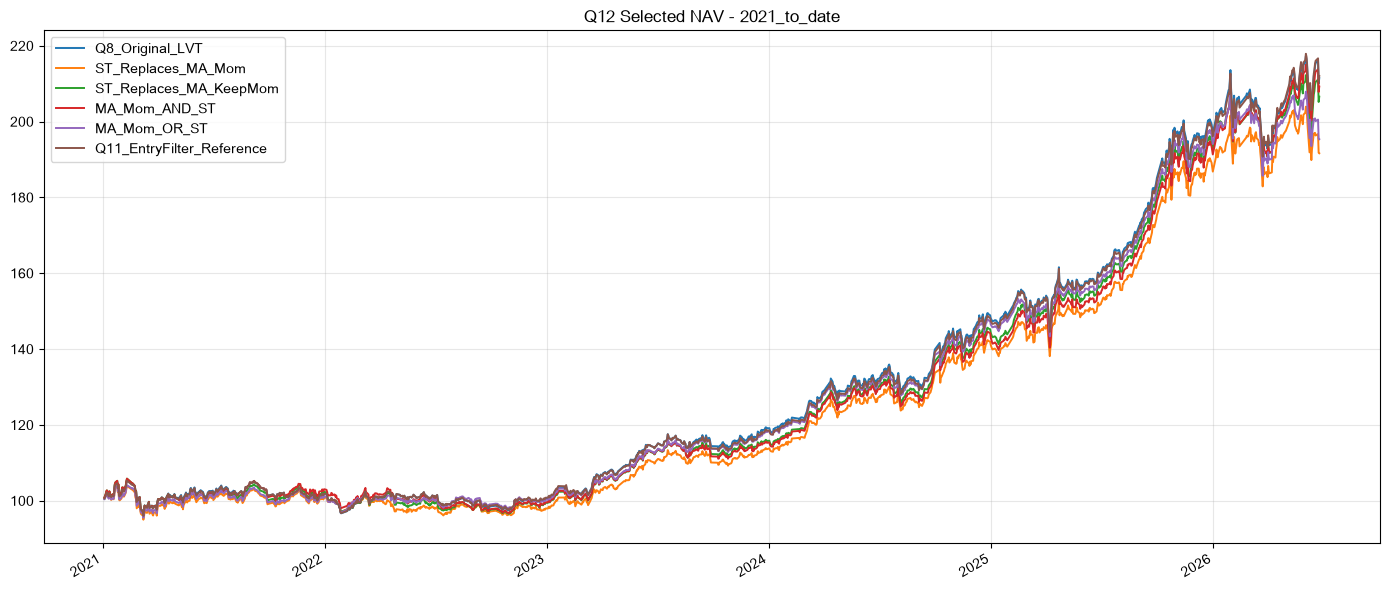

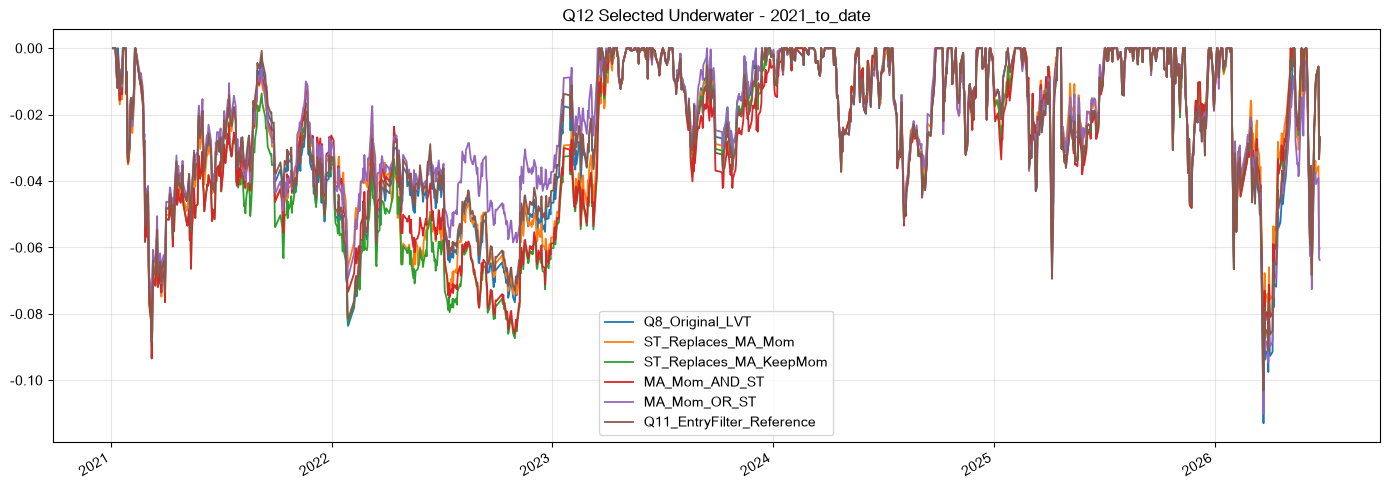

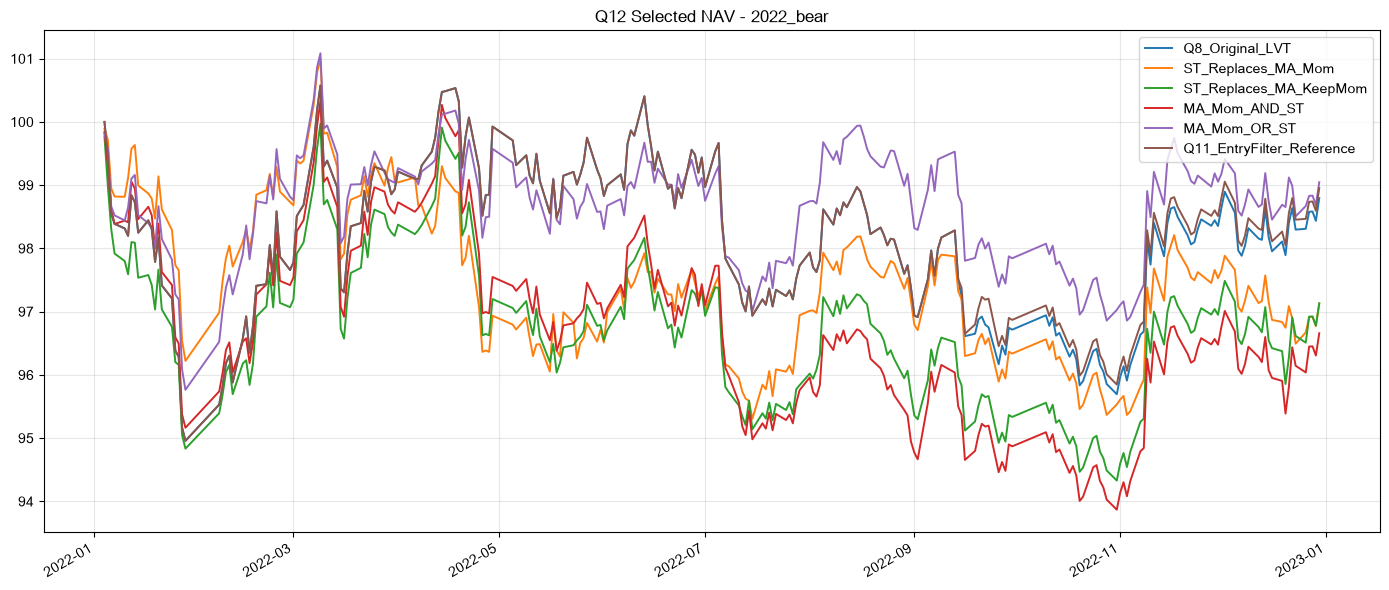

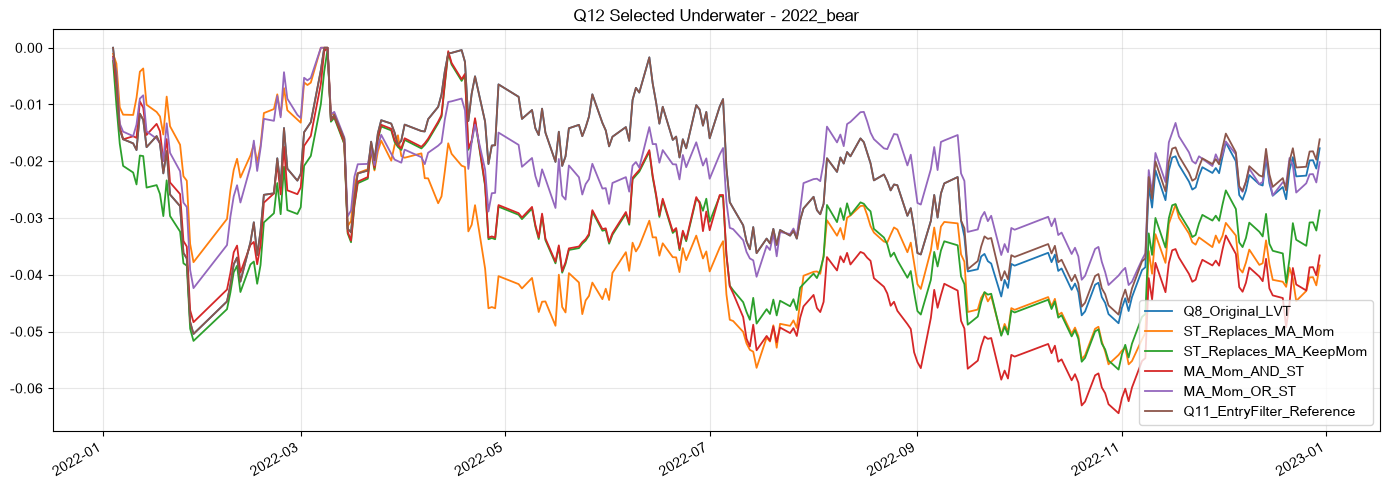

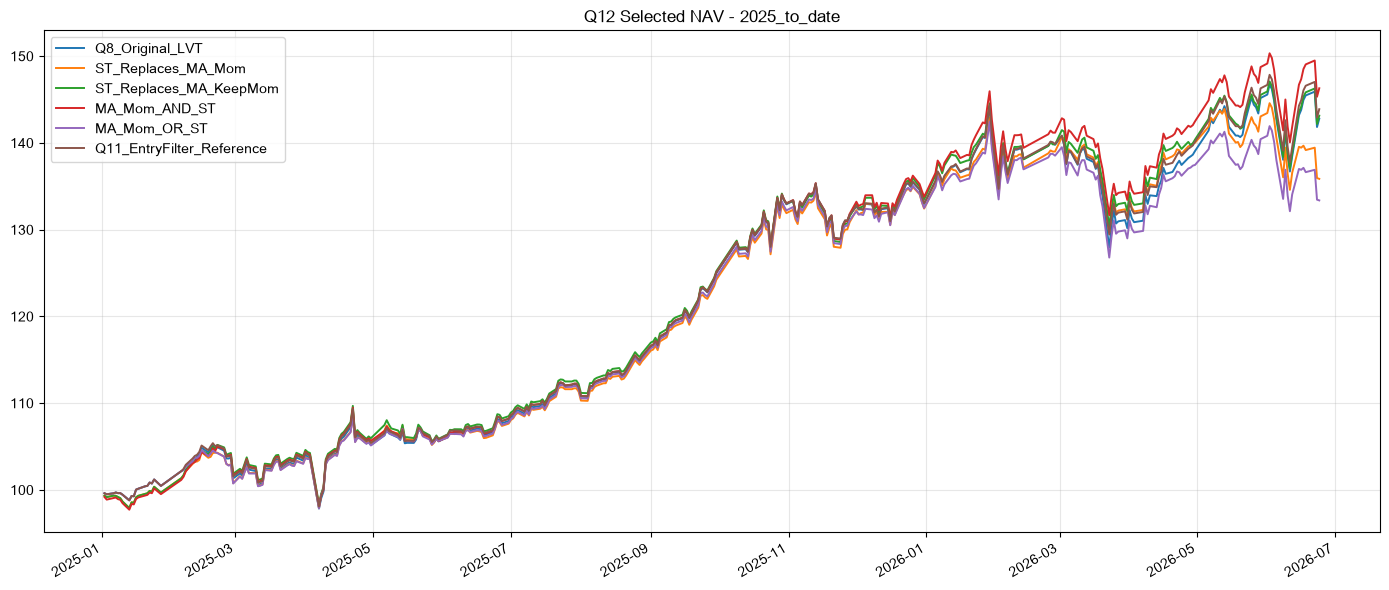

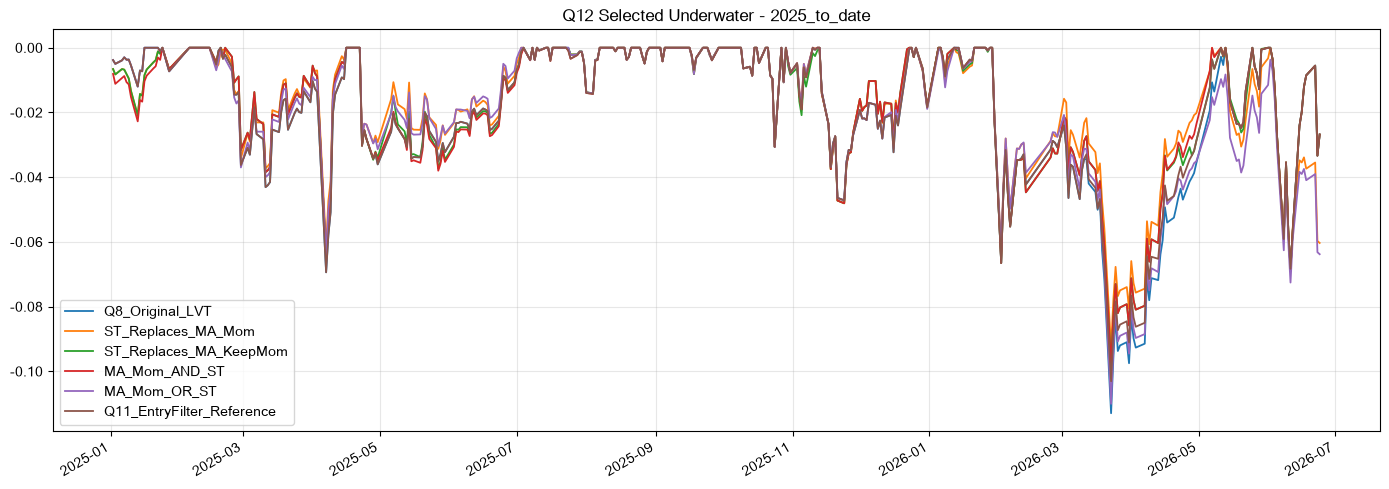

In [8]:
chart_names = list(STRATEGY_DEFINITIONS)
for window, (start, end) in {k: WINDOWS[k] for k in ["2021_to_date", "2022_bear", "2025_to_date"]}.items():
    navs = {}
    for name in chart_names:
        r = period_slice(portfolios[name]["returns"], start, end).fillna(0.0)
        navs[name] = nav_from_returns(r)
    nav_df = pd.DataFrame(navs)
    uw_df = nav_df.apply(drawdown_series)
    nav_df.to_csv(OUTPUT_DIR / f"nav_selected_{window}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_selected_{window}.csv", encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(14, 6))
    nav_df.plot(ax=ax, linewidth=1.4)
    ax.set_title(f"Q12 Selected NAV - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"nav_selected_{window}.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(14, 5))
    uw_df.plot(ax=ax, linewidth=1.3)
    ax.set_title(f"Q12 Selected Underwater - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"underwater_selected_{window}.png", dpi=160)
    plt.show()


## selector 诊断与 forward return


In [9]:
def forward_return(sym, loc, horizon):
    start_loc = loc + 1
    end_loc = loc + horizon + 1
    if start_loc >= len(close.index) or end_loc >= len(close.index):
        return np.nan
    start_price = close[sym].iloc[start_loc]
    end_price = close[sym].iloc[end_loc]
    if pd.isna(start_price) or pd.isna(end_price) or start_price <= 0:
        return np.nan
    return end_price / start_price - 1.0


selector_rows = []
forward_rows = []
for date in sorted(SDATES):
    loc = close.index.get_loc(date)
    selected_by_kind = {kind: set(select_assets(kind, date)) for kind in STRATEGY_DEFINITIONS if kind != "Q11_EntryFilter_Reference"}
    original = selected_by_kind["Q8_Original_LVT"]
    st_replacement = selected_by_kind["ST_Replaces_MA_Mom"]
    for kind, selected in selected_by_kind.items():
        selector_rows.append({
            "date": date,
            "strategy": kind,
            "selected_count": len(selected),
            "overlap_with_original": len(selected & original),
            "overlap_share_with_original": len(selected & original) / len(original) if len(original) else np.nan,
            "cash_signal": len(selected) == 0,
        })
    for sym in EXPANDED_THEME:
        orig_pass = sym in original
        st_pass = sym in st_replacement
        if orig_pass and st_pass:
            group = "both_selected"
        elif orig_pass and not st_pass:
            group = "original_only"
        elif (not orig_pass) and st_pass:
            group = "st_replacement_only"
        else:
            group = "neither"
        for h in [10, 20, 40]:
            forward_rows.append({
                "date": date,
                "symbol": sym,
                "name": SYMBOL_NAMES[sym],
                "group": group,
                "horizon": h,
                "forward_return": forward_return(sym, loc, h),
            })

selector_detail = pd.DataFrame(selector_rows)
selector_summary = selector_detail.groupby("strategy").agg(
    signal_dates=("date", "count"),
    average_selected_count=("selected_count", "mean"),
    cash_signal_rate=("cash_signal", "mean"),
    average_overlap_share_with_original=("overlap_share_with_original", "mean"),
).reset_index()
forward_detail = pd.DataFrame(forward_rows).dropna(subset=["forward_return"])
forward_summary = forward_detail.groupby(["horizon", "group"]).agg(
    observations=("forward_return", "count"),
    mean_forward_return=("forward_return", "mean"),
    median_forward_return=("forward_return", "median"),
    win_rate=("forward_return", lambda x: (x > 0).mean()),
    worst=("forward_return", "min"),
    best=("forward_return", "max"),
).reset_index()

selector_detail.to_csv(OUTPUT_DIR / "selector_overlap_detail.csv", index=False, encoding="utf-8-sig")
selector_summary.to_csv(OUTPUT_DIR / "selector_overlap_summary.csv", index=False, encoding="utf-8-sig")
forward_detail.to_csv(OUTPUT_DIR / "forward_return_original_vs_st_detail.csv", index=False, encoding="utf-8-sig")
forward_summary.to_csv(OUTPUT_DIR / "forward_return_original_vs_st_summary.csv", index=False, encoding="utf-8-sig")

display(selector_summary.round(4))
display(forward_summary.round(4))


,strategy,signal_dates,average_selected_count,cash_signal_rate,average_overlap_share_with_original
0,MA_Mom_AND_ST,154,2.2468,0.0909,0.7698
1,MA_Mom_OR_ST,154,2.7857,0.0325,0.8186
2,Q8_Original_LVT,154,2.5325,0.0455,1.0000
3,ST_Replaces_MA_KeepMom,154,2.3377,0.0714,0.7494
4,ST_Replaces_MA_Mom,154,2.7078,0.0390,0.6565


,horizon,group,observations,mean_forward_return,median_forward_return,win_rate,worst,best
0,10,both_selected,255,0.0097,0.0069,0.5804,-0.1444,0.3399
1,10,neither,951,0.0031,-0.0007,0.4921,-0.6635,0.3510
2,10,original_only,132,0.0085,0.0025,0.5303,-0.1283,0.1692
3,10,st_replacement_only,159,-0.0000,-0.0018,0.4528,-0.1391,0.2512
4,20,both_selected,255,0.0178,0.0091,0.6078,-0.1911,0.2353
5,20,neither,951,0.0075,0.0024,0.5068,-0.6657,0.4852
6,20,original_only,132,0.0070,0.0056,0.5303,-0.1487,0.2843
7,20,st_replacement_only,159,0.0108,0.0034,0.5346,-0.1862,0.4540
8,40,both_selected,250,0.0255,0.0246,0.6520,-0.1856,0.3217
9,40,neither,934,0.0198,0.0093,0.5343,-0.6573,0.7002


## SuperTrend 参数敏感性


In [10]:
sensitivity_kinds = ["ST_Replaces_MA_Mom", "ST_Replaces_MA_KeepMom", "MA_Mom_AND_ST", "MA_Mom_OR_ST"]
sensitivity_rows = []
baseline_2021 = summary_all[(summary_all["window"] == "2021_to_date") & (summary_all["strategy"] == "Q8_Original_LVT")].iloc[0]

for kind, atr, mult in product(sensitivity_kinds, [7, 10, 14], [2.0, 3.0, 4.0]):
    sat = build_satellite_weights(kind, atr=atr, multiplier=mult)
    target = combine_core_satellite(core_def200, sat)
    port = backtest(f"{kind}_ATR{atr}_M{mult:g}", target, sat)
    row = metrics_row(kind, port, "2021-01-01", None)
    row["strategy"] = kind
    row["atr"] = atr
    row["multiplier"] = mult
    row["is_default"] = atr == DEFAULT_ATR and float(mult) == DEFAULT_MULTIPLIER
    row["delta_年化收益_vs_Q8"] = row["年化收益"] - baseline_2021["年化收益"]
    row["delta_Calmar_vs_Q8"] = row["Calmar"] - baseline_2021["Calmar"]
    row["delta_最大回撤_vs_Q8"] = row["最大回撤"] - baseline_2021["最大回撤"]
    sensitivity_rows.append(row)

parameter_sensitivity = pd.DataFrame(sensitivity_rows)
parameter_sensitivity["Calmar_rank_in_strategy"] = parameter_sensitivity.groupby("strategy")["Calmar"].rank(ascending=False, method="min")
parameter_sensitivity["Sharpe_rank_in_strategy"] = parameter_sensitivity.groupby("strategy")["Sharpe"].rank(ascending=False, method="min")
parameter_sensitivity.to_csv(OUTPUT_DIR / "supertrend_internal_parameter_sensitivity.csv", index=False, encoding="utf-8-sig")

display(parameter_sensitivity[[
    "strategy", "atr", "multiplier", "is_default", "累计收益", "年化收益", "最大回撤", "Sharpe", "Calmar", "Sortino",
    "最长水下天数", "超过-10%天数", "平均现金/Def200权重", "年化换手", "年化成本拖累", "Calmar_rank_in_strategy", "Sharpe_rank_in_strategy"
]].sort_values(["strategy", "Calmar_rank_in_strategy"]).round(4))

param_shape = parameter_sensitivity.groupby("strategy").agg(
    cases=("Calmar", "count"),
    ann_min=("年化收益", "min"),
    ann_median=("年化收益", "median"),
    ann_max=("年化收益", "max"),
    calmar_min=("Calmar", "min"),
    calmar_median=("Calmar", "median"),
    calmar_max=("Calmar", "max"),
    maxdd_min=("最大回撤", "min"),
    maxdd_max=("最大回撤", "max"),
).reset_index()
param_shape.to_csv(OUTPUT_DIR / "supertrend_internal_parameter_sensitivity_summary.csv", index=False, encoding="utf-8-sig")
display(param_shape.round(4))


,strategy,atr,multiplier,is_default,累计收益,年化收益,最大回撤,Sharpe,Calmar,Sortino,最长水下天数,超过-10%天数,平均现金/Def200权重,年化换手,年化成本拖累,Calmar_rank_in_strategy,Sharpe_rank_in_strategy
18,MA_Mom_AND_ST,7,2.0,False,1.1923,0.1611,-0.0979,1.4778,1.6464,1.4070,185,0,0.1786,6.9234,0.0201,1.0,1.0
21,MA_Mom_AND_ST,10,2.0,False,1.1721,0.1591,-0.0979,1.4568,1.6254,1.3804,326,0,0.1789,7.0170,0.0204,2.0,2.0
22,MA_Mom_AND_ST,10,3.0,True,1.0922,0.1509,-0.0979,1.3840,1.5413,1.3101,518,0,0.1715,6.6879,0.0195,3.0,6.0
25,MA_Mom_AND_ST,14,3.0,False,1.1884,0.1607,-0.1081,1.4534,1.4872,1.3779,506,1,0.1732,6.8739,0.0201,4.0,3.0
23,MA_Mom_AND_ST,10,4.0,False,1.1017,0.1519,-0.1027,1.4081,1.4779,1.3348,535,1,0.1706,6.2610,0.0181,5.0,4.0
26,MA_Mom_AND_ST,14,4.0,False,1.0387,0.1452,-0.1042,1.3396,1.3934,1.2664,545,9,0.1689,6.3802,0.0186,6.0,8.0
19,MA_Mom_AND_ST,7,3.0,False,1.0769,0.1493,-0.1081,1.3686,1.3809,1.2891,536,1,0.1733,6.6009,0.0192,7.0,7.0
24,MA_Mom_AND_ST,14,2.0,False,1.1067,0.1524,-0.1110,1.3920,1.3729,1.3209,330,1,0.1806,7.0036,0.0203,8.0,5.0
20,MA_Mom_AND_ST,7,4.0,False,1.0430,0.1457,-0.1121,1.3394,1.2993,1.2675,537,7,0.1707,6.2175,0.0180,9.0,9.0
35,MA_Mom_OR_ST,14,4.0,False,1.0298,0.1442,-0.1047,1.3787,1.3773,1.2937,281,1,0.1604,5.9397,0.0170,1.0,2.0


,strategy,cases,ann_min,ann_median,ann_max,calmar_min,calmar_median,calmar_max,maxdd_min,maxdd_max
0,MA_Mom_AND_ST,9,0.1452,0.1519,0.1611,1.2993,1.4779,1.6464,-0.1121,-0.0979
1,MA_Mom_OR_ST,9,0.1350,0.1381,0.1471,1.2269,1.2599,1.3773,-0.1100,-0.1047
2,ST_Replaces_MA_KeepMom,9,0.1385,0.1481,0.1562,1.2187,1.3979,1.5951,-0.1136,-0.0979
3,ST_Replaces_MA_Mom,9,0.1311,0.1375,0.1423,1.2166,1.3350,1.4797,-0.1077,-0.0927


## 当前信号与 review note


In [11]:
latest_date = close.index[-1]
latest_signal_date = max(d for d in SDATES if d <= latest_date)
latest_signal_rows = []
for kind in STRATEGY_DEFINITIONS:
    selected = select_assets(kind, latest_signal_date) if kind != "Q11_EntryFilter_Reference" else select_assets(kind, latest_signal_date)
    latest_signal_rows.append({
        "strategy": kind,
        "signal_date": latest_signal_date.date(),
        "data_date": latest_date.date(),
        "selected_symbols": ",".join(selected),
        "selected_names": ",".join(SYMBOL_NAMES[sym] for sym in selected),
        "selected_count": len(selected),
    })
latest_signal_summary = pd.DataFrame(latest_signal_rows)
latest_signal_summary.to_csv(OUTPUT_DIR / "latest_signal_summary.csv", index=False, encoding="utf-8-sig")
display(latest_signal_summary)

research_summary = pd.Series({
    "data_start": str(close.index[0].date()),
    "data_end": str(close.index[-1].date()),
    "latest_signal_date": str(latest_signal_date.date()),
    "baseline": "Q8_Original_LVT / Core80 Expanded satellite20 Def200 Cash / BIMONTHLY / next_close / base20_plus_asset",
    "default_supertrend": f"ATR{DEFAULT_ATR}_multiplier{DEFAULT_MULTIPLIER:g}",
})
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")
research_summary


,strategy,signal_date,data_date,selected_symbols,selected_names,selected_count
0,Q8_Original_LVT,2026-06-10,2026-06-24,"513100.SS,515880.SS,159995.SZ","纳指100ETF,通信ETF,芯片ETF",3
1,ST_Replaces_MA_Mom,2026-06-10,2026-06-24,"510880.SS,159930.SZ,513100.SS","红利ETF,能源ETF,纳指100ETF",3
2,ST_Replaces_MA_KeepMom,2026-06-10,2026-06-24,"513100.SS,515880.SS,159995.SZ","纳指100ETF,通信ETF,芯片ETF",3
3,MA_Mom_AND_ST,2026-06-10,2026-06-24,"513100.SS,515880.SS,159995.SZ","纳指100ETF,通信ETF,芯片ETF",3
4,MA_Mom_OR_ST,2026-06-10,2026-06-24,"510880.SS,159930.SZ,513100.SS","红利ETF,能源ETF,纳指100ETF",3
5,Q11_EntryFilter_Reference,2026-06-10,2026-06-24,"513100.SS,515880.SS,159995.SZ","纳指100ETF,通信ETF,芯片ETF",3


data_start                                                   2020-01-02
data_end                                                     2026-06-24
latest_signal_date                                           2026-06-10
baseline              Q8_Original_LVT / Core80 Expanded satellite20 ...
default_supertrend                                    ATR10_multiplier3
dtype: str

In [12]:
def pct(x):
    if pd.isna(x):
        return "n/a"
    return f"{x:.2%}"


def num(x):
    if pd.isna(x):
        return "n/a"
    return f"{x:.2f}"


main_2021 = summary_all[summary_all["window"] == "2021_to_date"].copy()
historical_best = main_2021.sort_values("累计收益", ascending=False).iloc[0]
risk_best = main_2021.sort_values("Sharpe", ascending=False).iloc[0]
calmar_best = main_2021.sort_values("Calmar", ascending=False).iloc[0]

balanced = main_2021.copy()
for col, ascending in [("年化收益", False), ("Calmar", False), ("Sharpe", False), ("最大回撤", False), ("年化换手", True), ("平均现金/Def200权重", True)]:
    balanced[f"rank_{col}"] = balanced[col].rank(ascending=ascending, method="min")
balanced["balanced_rank_sum"] = balanced[[c for c in balanced.columns if c.startswith("rank_")]].sum(axis=1)
balanced_best = balanced.sort_values("balanced_rank_sum").iloc[0]

default_params = parameter_sensitivity[parameter_sensitivity["is_default"]].copy()

main_cols = ["strategy", "累计收益", "年化收益", "最大回撤", "Sharpe", "Calmar", "Sortino", "最长水下天数", "超过-10%天数", "平均现金/Def200权重", "平均卫星现金", "年化换手", "年化成本拖累"]
window_cols = ["window", "strategy", "累计收益", "最大回撤", "Sharpe", "Calmar", "最长水下天数", "超过-10%天数", "年化换手", "年化成本拖累", "平均现金/Def200权重"]

note = f"""# Q12 SuperTrend 替代 LVT 内部趋势确认 Review

Date: {pd.Timestamp.today().date()}

## 研究问题

Q12 回答：如果直接把 LVT 内部的趋势确认换成 SuperTrend，会不会比 Q8 原始 LVT 更好？

Q8 实盘化口径保持不变：

- Core80 / Expanded satellite20 / Def200 Cash
- fixed twice-monthly signal
- close-signal-next-day-trade
- 20 bps base cost + asset friction
- 2% minimum rebalance threshold
- 15% max single-ETF trade cap

本次只改变 Expanded satellite 的 selector，低波排序、Top3、RiskParity cap50、执行、成本和窗口全部相同。

## 策略定义

| 策略 | 通俗定义 |
|---|---|
| `Q8_Original_LVT` | 原始 LVT：MA60 上方 + 63 日动量为正，然后选低波 Top3。 |
| `ST_Replaces_MA_Mom` | 直接替换：只要 SuperTrend 多头，然后选低波 Top3。 |
| `ST_Replaces_MA_KeepMom` | 只替换 MA：SuperTrend 多头 + 63 日动量为正，然后选低波 Top3。 |
| `MA_Mom_AND_ST` | 严格双确认：原始 LVT 条件和 SuperTrend 都要通过。 |
| `MA_Mom_OR_ST` | 宽松确认：原始 LVT 条件或 SuperTrend 任一通过。 |
| `Q11_EntryFilter_Reference` | Q11 外层准入过滤参考，不是内部替换。 |

## 2021 至今主结果

{main_2021[main_cols].to_markdown(index=False)}

## 分窗口结果

{summary_all[summary_all['strategy'].isin(list(STRATEGY_DEFINITIONS))][window_cols].sort_values(['window', 'strategy']).to_markdown(index=False)}

## Selector 诊断

{selector_summary.to_markdown(index=False)}

## Forward return：原始 LVT 选中 vs ST 替代选中

{forward_summary.to_markdown(index=False)}

## 参数敏感性摘要

{param_shape.to_markdown(index=False)}

默认参数排名：

{default_params[['strategy', 'atr', 'multiplier', 'Calmar', 'Sharpe', 'Calmar_rank_in_strategy', 'Sharpe_rank_in_strategy']].sort_values('strategy').to_markdown(index=False)}

## 结论

### Historical best

2021 至今历史收益最高的是 `{historical_best['strategy']}`，累计收益 {pct(historical_best['累计收益'])}。Q8 原始 LVT 为 {pct(baseline_2021['累计收益'])}。

### Risk-adjusted best

按 Sharpe 最好的是 `{risk_best['strategy']}`，Sharpe {num(risk_best['Sharpe'])}。按 Calmar 最好的是 `{calmar_best['strategy']}`，Calmar {num(calmar_best['Calmar'])}。

### Most structurally balanced

综合收益、Sharpe、Calmar、回撤、换手和现金暴露，最均衡的是 `{balanced_best['strategy']}`。

### SuperTrend 替代 LVT 趋势确认是否有帮助

结论要分层：

- 直接用 SuperTrend 替代 MA60+动量，不是明显升级；需要看它是否提高收益，同时不只是靠改变暴露或提高换手。
- 如果保留动量、只把 MA60 换成 ST，通常比完全替代更合理，因为它没有把 LVT 的趋势强度约束全部拿掉。
- 严格 AND 版本更像防守确认，容易改善回撤但也可能牺牲上涨。
- 宽松 OR 版本更像扩大候选池，可能提高收益，但更容易把趋势质量放松。

### 与 Q11 的关系

Q11 的最好用法是“外层准入过滤”。Q12 检验的是“内层趋势模块替换”。如果 Q12 内部替换没有明显胜过 `Q11_EntryFilter_Reference`，那说明 SuperTrend 更适合做外层确认灯，而不是替代 LVT 的原始趋势定义。

### 下一步建议

如果要进入纸面跟踪，不建议直接替换 Q8。更稳妥的是：

1. 继续以 `Q8_Original_LVT` 为主基准；
2. 保留 `Q11_EntryFilter_Reference` 作为外层确认候选；
3. 仅把 Q12 中排名靠前且参数敏感性不过度依赖单点的内部替换版本，作为研究候选。

## 文件

- Notebook: `q12-supertrend-replace-lvt-trend-confirmation-practice.ipynb`
- Outputs: `outputs/q12-supertrend-replace-lvt-trend-confirmation/`
- Main summary: `summary_all_windows.csv`
- Parameter sensitivity: `supertrend_internal_parameter_sensitivity.csv`
- Selector diagnostics: `selector_overlap_summary.csv`
- Forward diagnostics: `forward_return_original_vs_st_summary.csv`
"""

Path("docs/notes").mkdir(parents=True, exist_ok=True)
review_path = Path("docs/notes/q12-supertrend-replace-lvt-trend-confirmation-review.md")
review_path.write_text(note, encoding="utf-8")
print(review_path)


docs/notes/q12-supertrend-replace-lvt-trend-confirmation-review.md
